# The DFTHC walk operator details

`DFTHCWalk` is the qubitization walk operator of the DFTHC block encoding. This notebook builds it and takes apart its bloqs and costings.

In [1]:
import numpy as np
import sympy
from qualtran.drawing import show_bloq, show_call_graph
from qualtran.resource_counting import (
    get_bloq_callee_counts, get_cost_value, QECGatesCost, QubitCount,
)

from dfthcbe import DFTHCBlockEncoding, DFTHCWalk, InnerPrepare, InnerSelect, Maj, OuterPrepare

E0000 00:00:1793786805.673860   20914 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793786805.673945   20914 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1793786805.673952   20914 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793786805.673957   20914 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1793786805.673961   20914 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.


## 1. Three example cases

We show three walk operator examples here:

- `tiny`, assembled from its three sub-bloqs with system size $N = 3$ and DFTHC parameters $(R, B, C) = (2, 7, 2)$: small enough to draw and simulate.
- `Fe4S4` from the DFTHC fit of $\text{Fe}_4\text{S}_4$, $N = 36$ and $(R, B, C) = (33, 11, 3)$: the numbers of a real system;
- `symbolic` with every size a symbol: the closed forms. In this implementation the symbolic costs are *always* equal to the resolved costs.

$b_{\mathrm{rot}}$ (`b_rot`) is the bit precision of each Givens angle, $b_{k_1}$ and $b_{k_2}$ (`b_k1`, `b_k2`) those of the $\mathrm{keep}$ values of the outer and inner alias tables, and $s_u$ (`s`, 7 by default) those of the two rotations of each uniform superposition. $k_1, k_2$ are the log block sizes of the two QROAM reads, and $k_{e1}, k_{e2}$ the numbers of bits of $x_o$ in the one-hot of their erases; if not explicitly provided, they default to the cheapest. Throughout, $\lg y = \lceil \log_2 y \rceil$, which the cost prints show as `ceiling(log2(y))`. The tiny walk has $b_{\mathrm{rot}} = s_u = 4$, $b_{k_1} = b_{k_2} = 3$, $k_1 = 1$ and $k_2 = 2$, as in the figures, and random weights and vectors elsewhere.

In [2]:
KEYS = ('U', 'W', 'w_B', 'w_plus', 'u_plus', 'w_minus', 'u_minus')
fe4s4 = np.load('../data/dfthc/fe4s4/factors.npz')

rng = np.random.default_rng(7)
w_sf = rng.standard_normal((2, 2, 8))  # the inner weights, (R, C, B + 1)
w_sf[1, 1] = [0.30, -0.20, 0.14, -0.12, 0.10, -0.06, 0.05, -0.03]  # row x_o = 3 of sec. 5
tiny = DFTHCBlockEncoding(
    outer=OuterPrepare.from_weights([0.25, 0.20, 0.15, 0.12, 0.10, 0.10, 0.08], b_k1=3,
                                    log_block_size=1, s=4, phase_grad_bitsize=4),
    inner=InnerPrepare.from_coeffs(w_sf, num_orb=3, b_k2=3, log_block_size=2, s=4,
                                   phase_grad_bitsize=4),
    select=InnerSelect.from_vectors(rng.standard_normal((2, 7, 3)), rng.standard_normal((2, 3)),
                                    rng.standard_normal((1, 3)), num_c=2, b_rot=4),
)

walks = {
    'tiny': DFTHCWalk(tiny),
    'Fe4S4': DFTHCWalk.from_factors(**{k: fe4s4[k] for k in KEYS}, b_rot=15, b_k1=15, b_k2=15),
    'symbolic': DFTHCWalk.symbolic(*sympy.symbols('N R B C b_rot b_k1 b_k2 k_1 k_2 k_e1 k_e2 s_u')),
}

The Toffoli count comes from Qualtran's call graph. `total_toffoli_only()` adds the Toffolis, CSWAPs and `And`s, and raises if any T gate or rotation is left, so the count is complete. `QubitCount` gives the qubits.

In [3]:
for name in ('tiny', 'Fe4S4'):
    walk = walks[name]
    toffolis = get_cost_value(walk, QECGatesCost()).total_toffoli_only()
    print(f'{name}: {toffolis} Toffolis, {get_cost_value(walk, QubitCount())} qubits')

tiny: 305 Toffolis, 88 qubits


Fe4S4: 6334 Toffolis, 898 qubits


## 2. The walk

$W = \mathrm{REF}_{a \cup B} \cdot \mathrm{BE}[H_{\mathrm{SA}} / \Lambda - I]$: the block encoding (steps 1-27), then the reflection $\mathrm{REF}_{a \cup B}$ on all ancillas (step 28).

![The walk operator, one box per bloq](../docs/dfthc-walk.svg)

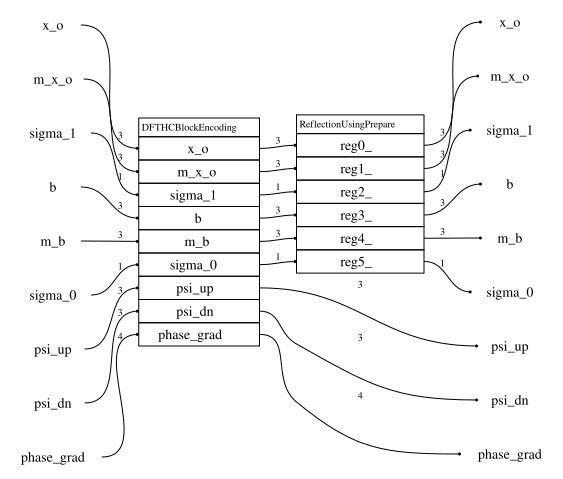

In [4]:
show_bloq(walks['tiny'].decompose_bloq())

## 3. The block encoding $\mathrm{BE}[H_{\mathrm{SA}} / \Lambda - I]$

$\mathrm{BE}[H_{\mathrm{SA}} / \Lambda - I] = U^\dagger\, \mathrm{REF}_{T_2}\, U$, steps 1-27. The figure shows steps 1-23; after them steps 5-22 run again, inverted, and steps 24-27 undo 1-4.

![Steps 1-23 of the block encoding](../docs/dfthc-block-encoding.svg)

To show how this block encoding is implemented, let's take the tiny walk:

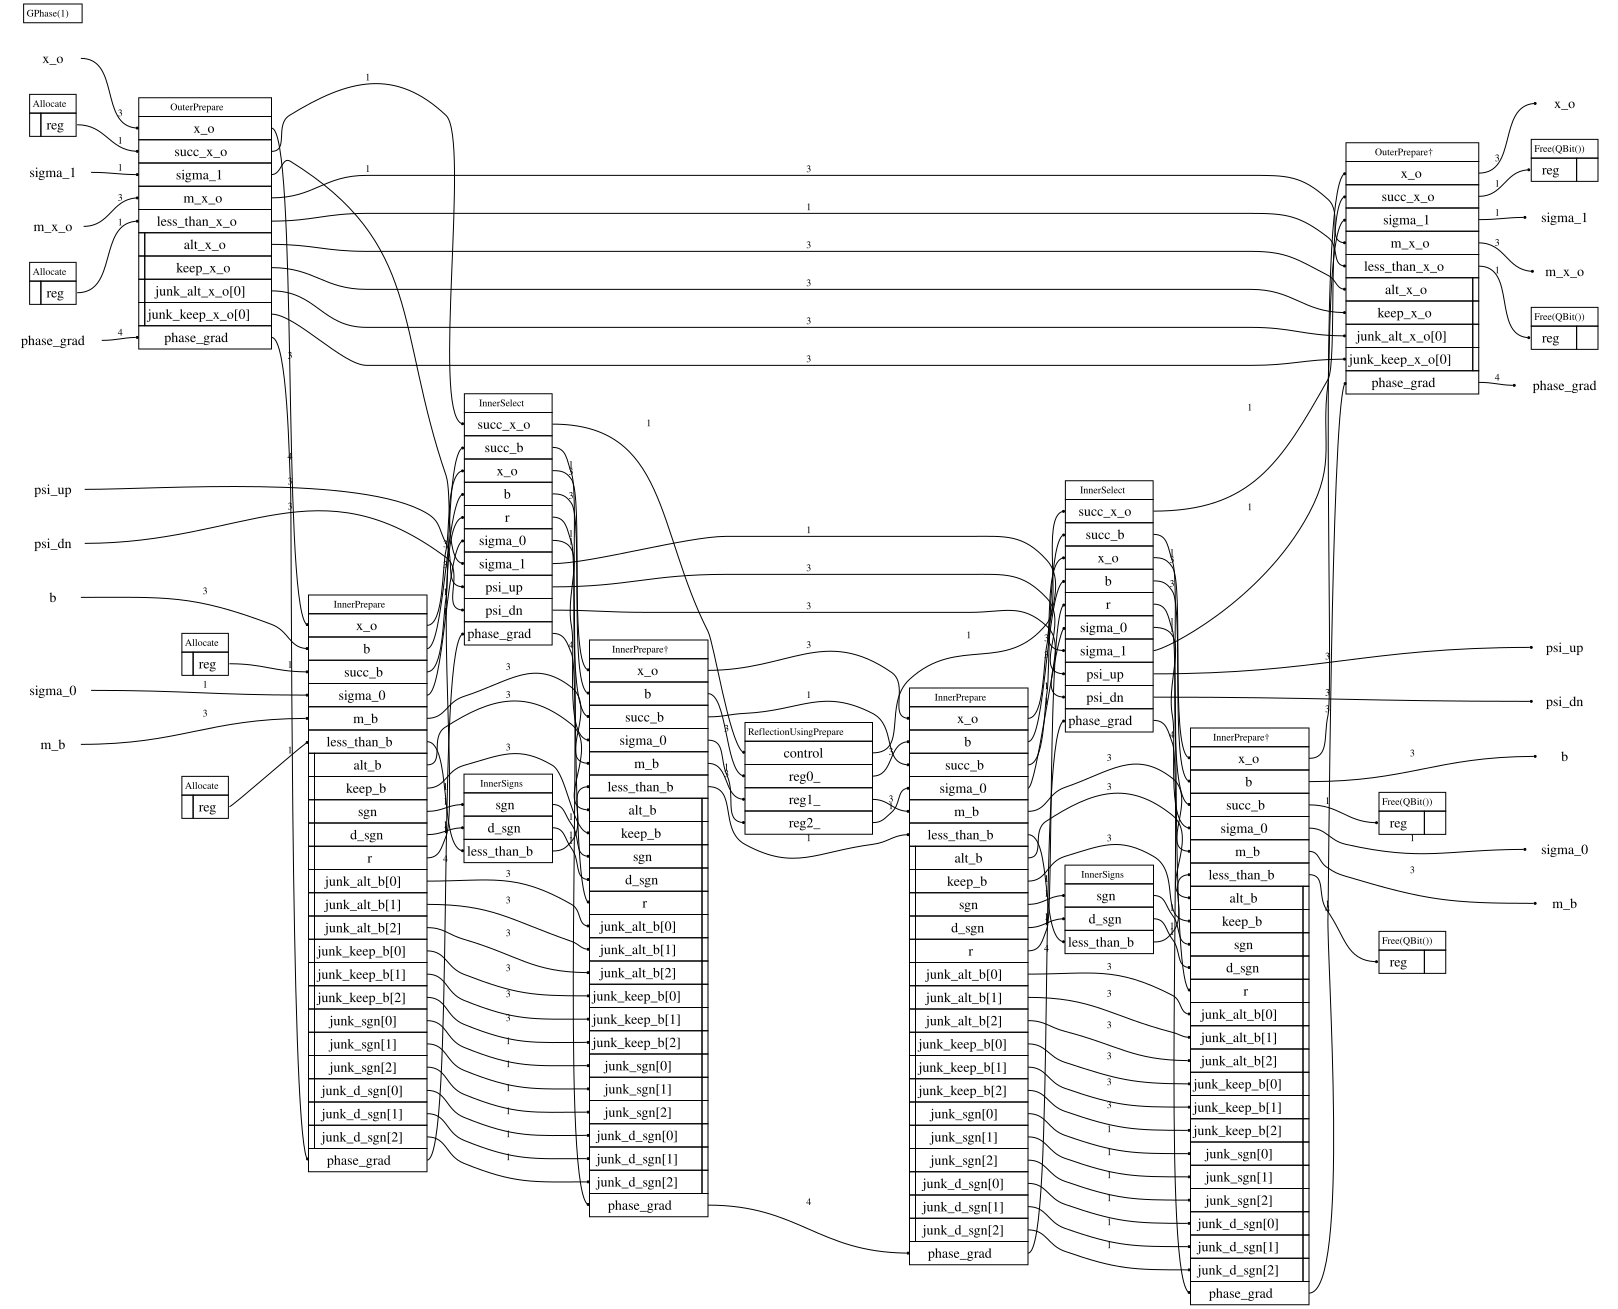

In [5]:
show_bloq(walks['tiny'].block_encoding.decompose_bloq())

To make sense of this large bloq, let's divide it into its sub-bloqs and look at them individually. Each is an attribute: `.outer`, `.inner`, `.select` and `.ref_t2` of `walk.block_encoding`, and `.ref_ab` of the walk; the inverted boxes are their `.adjoint()`.

## 4. Steps 1-4: `OuterPrepare`

`OuterPrepare` prepares the state:

$$
\begin{equation*}
  |0\rangle \;\xrightarrow{\;1-4\;}\;
  \frac{1}{\lambda_{\mathrm{sqrt}}}\sum_{x_o=0}^{X_o-1}
     \lambda_{x_o}\,|x_o\rangle\,|\mathrm{garb}_{x_o}\rangle ,
  \qquad
  \lambda^2_{x_o} =
  \begin{cases}
    2w^{(r)}_{\pm}, & \text{a $D_1$ or $Q_1$ row},\\[2pt]
    \lambda^2_{\mathrm{SF},rc}, & \text{an SF row},
  \end{cases}
\end{equation*}
$$

To do this, we make use of alias sampling. Classically, `alias_table` writes the distribution $p_{x_o} = \lambda^2_{x_o} / \lambda^2_{\mathrm{sqrt}}$ over the $X_o = N + RC$ values as two columns, $\mathrm{alt}$ and $\mathrm{keep}$: drawing $x_o$ uniformly, keeping it with probability $\mathrm{keep}(x_o) / 2^{b_{k_1}}$ and otherwise taking $\mathrm{alt}(x_o)$ gives $p_{x_o}$ to $b_{k_1}$ bits. The circuit does the same coherently:

1. an equal superposition is prepared over the $X_o$ values of $x_o$, with $\mathrm{succ}_{x_o}$ flagging its success;
2. Hadamards on the $b_{k_1}$ qubits of $m_{x_o}$;
3. a Hadamard puts the outer spin $\sigma_1$, which the D1/Q1 generators read, in $|+\rangle$;
4. a QROAM loads $\mathrm{alt}(x_o)$ and $\mathrm{keep}(x_o)$;
5. a flag marks $\mathrm{keep}(x_o) \leq m_{x_o}$, which happens with probability $1 - \mathrm{keep}(x_o) / 2^{b_{k_1}}$;
6. controlled on the output of the previous comparison, $\mathrm{alt}(x_o)$ is swapped into $x_o$.

All registers but $x_o$ and $\sigma_1$ make up $|\mathrm{garb}_{x_o}\rangle$, which steps 24-27 undo. For the tiny walk, $X_o = 7$, $b_{k_1} = 3$ and $K_1 = 2$:

![Steps 1-4](../docs/dfthc-outer-prepare.svg)


The full bloq is shown here for the tiny example:

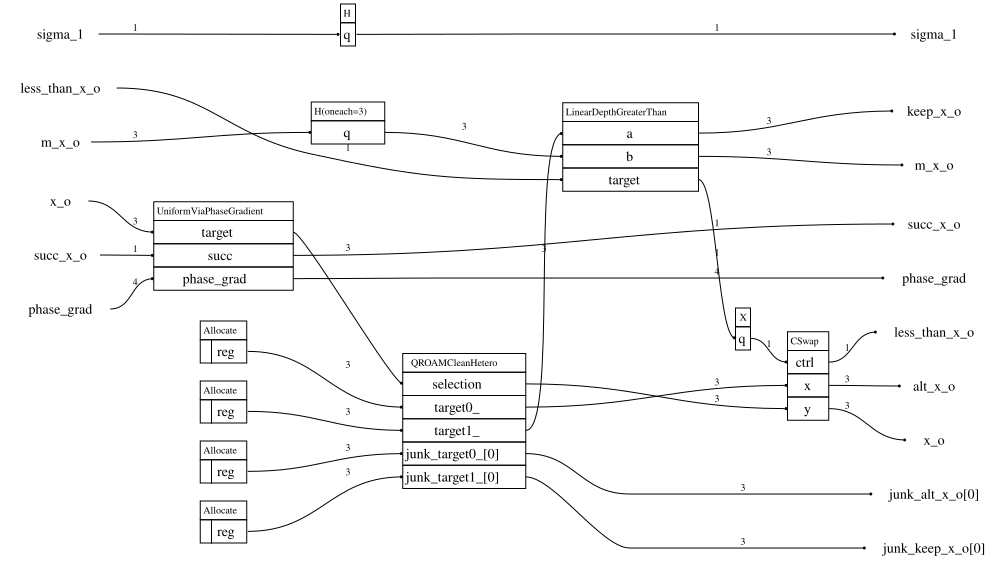

In [6]:
show_bloq(walks['tiny'].block_encoding.outer.decompose_bloq())

Let's go through this bloq moment by moment. The first step is preparing a uniform superposition. If $X_o$ is a power of 2, this is just Hadamards on every qubit. But in general, Qualtran's `PrepareUniformSuperposition` writes $X_o$ as a product $2^{\eta_x} l_x$ with $l_x$ odd: Hadamards on the $\eta_x$ low qubits give the $2^{\eta_x}$, and on the $n_x = \lg l_x$ high qubits, $x_o^{\mathrm{hi}}$, one round of amplitude amplification gives exactly the $l_x$ values below $l_x$:

$$
\frac{1}{\sqrt{l_x}} \sum_{x_o^{\mathrm{hi}} < l_x} |x_o^{\mathrm{hi}}\rangle = H^{\otimes n_x}\, R_0(\theta)\, H^{\otimes n_x}\, R_{<l_x}(\theta)\, H^{\otimes n_x}\, |0\rangle, \qquad \theta = \arccos\left(1 - 2^{\lfloor \log_2 l_x \rfloor} / l_x\right),
$$

where $R_{<l_x}(\theta)$ puts the phase $e^{i\theta}$ on every $x_o^{\mathrm{hi}} < l_x$ and $R_0(\theta)$ on $x_o^{\mathrm{hi}} = 0$.

Each phase is a rotation, and every rotation in the walk is done the same way: by an addition into a phase-gradient state of $b_{\mathrm{rot}}$ qubits (Qualtran's `PhaseGradientState`),

$$
|\phi_{b_{\mathrm{rot}}}\rangle = \frac{1}{\sqrt{2^{b_{\mathrm{rot}}}}} \sum_{k=0}^{2^{b_{\mathrm{rot}}}-1} e^{-2\pi i k / 2^{b_{\mathrm{rot}}}}\, |k\rangle, \qquad |\phi_{b_{\mathrm{rot}}}\rangle \xrightarrow{\;+x\;} e^{2\pi i x / 2^{b_{\mathrm{rot}}}}\, |\phi_{b_{\mathrm{rot}}}\rangle .
$$

Adding an integer $x$ into it, controlled on a qubit, puts the phase $e^{2\pi i x / 2^{b_{\mathrm{rot}}}}$ on that qubit's $|1\rangle$ and leaves $|\phi_{b_{\mathrm{rot}}}\rangle$ as it was. `ZPowConstViaPhaseGradient` does so with $x$ the angle to $s_u$ bits, $\theta \approx 2\pi x / 2^{s_u}$, for $s_u - 2$ Toffolis. The walk's register `phase_grad` holds $|\phi_{b_{\mathrm{rot}}}\rangle$, prepared once before it: these two phases use its top $s_u$ qubits, the Givens rotations of sec. 6 all $b_{\mathrm{rot}}$. Rounding $\theta$ leaves a little amplitude on $x_o \geq X_o$, which $\mathrm{succ}_{x_o}$ flags; the values below $X_o$ stay exactly uniform.

The figure shows it gate by gate for the tiny walk's $X_o = 7$, odd, so all three qubits of $x_o$ are amplified: the phase on $x_o < 7$ (computed into $c$), Hadamards, the phase on $x_o = 0$ (through the ANDs into $j$ and $z$) and Hadamards; then the flag $\mathrm{succ}_{x_o}$. Each phase XORs $k = 2$, $\theta$ to $s_u = 4$ bits, into $t$ and adds it into $|\phi_4\rangle$. The bands count the Toffolis, 15 in all.

![Uniform prep](../docs/dfthc-uniform.svg)

Below is Qualtran's decomposition of the same bloq:

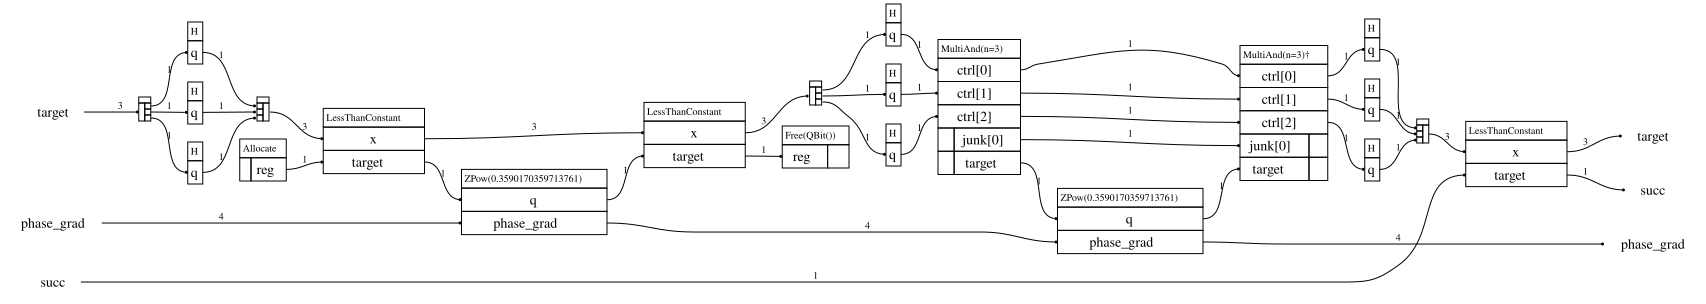

In [7]:
show_bloq(walks['tiny'].block_encoding.outer.uniform.decompose_bloq())

In [8]:
sym_outer = walks['symbolic'].block_encoding.outer
N, R, C = sympy.symbols('N R C')
X_o = sympy.Symbol('X_o', integer=True, positive=True)  # N + RC
n_x = sympy.Symbol('n_x', integer=True, nonnegative=True)  # the qubits of x_o amplified
SHORT = [(sym_outer.uniform.k_l_logL()[2], n_x), (N + R * C, X_o)]
uniform = get_cost_value(sym_outer.uniform, QECGatesCost()).total_toffoli_only()
print(sympy.collect(uniform.subs(SHORT), sympy.Min(1, n_x)))

(4*n_x + 2*s_u - 5)*Min(1, n_x)


`SHORT` only renames: $X_o = N + RC$ and $n_x = \lg l_x$. The bracket `Min(1, n_x)` is $[n_x > 0]$, 0 when $X_o$ is a power of two: there the Hadamards are exact and none of the rest runs. Term by term, $4 n_x + 2 s_u - 5$ is:

- $3 n_x$: the comparison $x_o^{\mathrm{hi}} < l_x$ (`LessThanConstant`, $n_x$ Toffolis), computed and uncomputed around the first phase, and once more into $\mathrm{succ}_{x_o}$;
- $n_x - 1$: the `MultiAnd` that finds $x_o^{\mathrm{hi}} = 0$ for the second phase; its uncompute is measured, for free;
- $2(s_u - 2)$: the two phases, $s_u - 2$ each.

After step 1, the uniform prepare and the Hadamards on $m_{x_o}$ ($2^{b_{k_1}}$ is a power of two) and $\sigma_1$, we load the $\mathrm{alt}$ and $\mathrm{keep}$ values with a QROAM (step 2). A QROAM over a table of $L$ entries reads $K = 2^k$ of them at once: a QROM writes the addressed block of $K$ entries into $K$ copies of the output, for $\lceil L/K \rceil - 2$ Toffolis, and $K - 1$ controlled swaps per output bit move the addressed entry into the first copy. The figure shows it for the seven entries of the tiny walk's table in blocks of $K = 2$, the last block padded with a zero, printed below: the QROM over the four blocks (2a), then the swap on $x_o[0]$ (2b), $2 + 6$ Toffolis. The second copy stays behind as junk until the erase.

![Step 2](../docs/dfthc-qroam-outer.svg)

Qualtran builds the same read, `QROAMCleanHetero`, from the same table: a `QROM` over the four blocks, then one `SwapWithZero` for $\mathrm{alt}$ and one for $\mathrm{keep}$.

alt  (0, 2, 2, 0, 0, 0, 1)
keep (0, 7, 0, 6, 6, 6, 4)


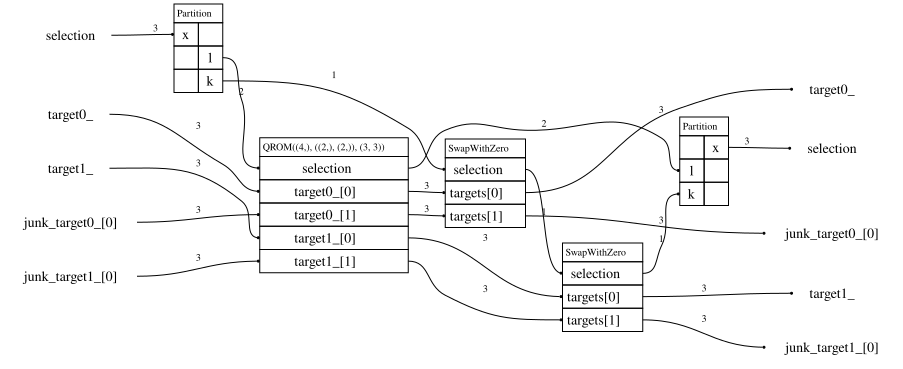

In [9]:
outer = walks['tiny'].block_encoding.outer
print('alt ', outer.alt)
print('keep', outer.keep)
show_bloq(outer.qroam.decompose_bloq())

In [10]:
print(get_cost_value(sym_outer.qroam, QECGatesCost()).total_toffoli_only().subs(SHORT))

b_k1*(2**k_1 - 1) + (2**k_1 - 1)*ceiling(log2(X_o)) + ceiling(X_o/2**k_1) - 2


With $K_1 = 2^{k_1}$: the QROM over the $\lceil X_o/K_1 \rceil$ blocks, $\lceil X_o/K_1 \rceil - 2$ Toffolis, and the swaps, $K_1 - 1$ per output bit for the $b_1 = \lg X_o + b_{k_1}$ bits of $\mathrm{alt}$ and $\mathrm{keep}$. A larger $K_1$ trades the first for the second; from a fit, `from_factors` takes the cheapest.

In [11]:
for bloq, n in get_bloq_callee_counts(sym_outer):
    toffolis = get_cost_value(bloq, QECGatesCost()).total_toffoli_only()
    print(f'{n} x {bloq}: {sympy.collect(sympy.S(toffolis).subs(SHORT), sympy.Min(1, n_x))}')
total = get_cost_value(sym_outer, QECGatesCost()).total_toffoli_only()
print('total:', sympy.collect(total.subs(SHORT), sympy.Min(1, n_x)))

1 x UniformViaPhaseGradient: (4*n_x + 2*s_u - 5)*Min(1, n_x)
1 x H(oneach=b_k1): 0
1 x H: 0
1 x QROAMCleanHetero: b_k1*(2**k_1 - 1) + (2**k_1 - 1)*ceiling(log2(X_o)) + ceiling(X_o/2**k_1) - 2
1 x LinearDepthGreaterThan: b_k1
1 x X: 0
1 x CSwap: ceiling(log2(X_o))
total: b_k1*(2**k_1 - 1) + b_k1 + (2**k_1 - 1)*ceiling(log2(X_o)) + (4*n_x + 2*s_u - 5)*Min(1, n_x) + ceiling(X_o/2**k_1) + ceiling(log2(X_o)) - 2


In [12]:
b_k1, k_1, s_u = sympy.symbols('b_k1 k_1 s_u')
total = get_cost_value(sym_outer, QECGatesCost()).total_toffoli_only().subs(N + R * C, X_o)
for name, walk in list(walks.items())[:2]:
    outer = walk.block_encoding.outer
    sizes = {X_o: outer.num_x, b_k1: outer.b_k1, k_1: outer.qroam.log_block_sizes[0], s_u: outer.s}
    built = get_cost_value(outer, QECGatesCost()).total_toffoli_only()
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

tiny: 29 built, 29 from the symbolic count
Fe4S4: 153 built, 153 from the symbolic count


## 5. Steps 5-8: `InnerPrepare`

The outer $\mathrm{SEL}$ is an inner LCU for each $x_o$:

$$\mathrm{SEL} = \sum_{x_o} \lvert x_o \rangle \langle x_o \rvert \otimes
  \mathrm{PREP}_{b, x_o}^\dagger \, \mathrm{SEL}_{b, x_o} \, \mathrm{PREP}_{b, x_o} .$$

So `InnerPrepare` prepares an inner superposition on an additional register $b$, which is, on each SF row $x_o < RC$, the signed LCU of $O_{\mathrm{SF},rc}$ over its $B$ terms and the identity term $b = B$. It also writes the rank $r$, which the angle load later reads. `InnerPrepare` thus gives the state:

$$
\begin{aligned}
\frac{1}{\lambda_{\mathrm{sqrt}}} \Big[ &\sum_{x_o < RC} \lambda_{x_o}\, |x_o\rangle |\mathrm{garb}_{x_o}\rangle\, |r\rangle \sum_{b=0}^{B} (-1)^{\mathrm{sgn}_b} \sqrt{q^{(r,c)}_b}\, |b\rangle\, |\mathrm{garb}^{(x_o)}_b\rangle \\
+ &\sum_{x_o \geq RC} \lambda_{x_o}\, |x_o\rangle |\mathrm{garb}_{x_o}\rangle\, |0\rangle_r\, |0\rangle_b\, |\mathrm{garb}'_{x_o}\rangle \Big] \otimes |+\rangle_{\sigma_0} |+\rangle_{\sigma_1}, \qquad q^{(r,c)}_b = \frac{|w^{(r,c)}_b|}{\sum_{b'} |w^{(r,c)}_{b'}|},
\end{aligned}
$$

with $(-1)^{\mathrm{sgn}_b}$ the sign of $w^{(r,c)}_b$. The $N$ D1/Q1 rows, $x_o \geq RC$, have no sum over $b$: their table rows are zero, so $b$ ends in $|0\rangle$. The read therefore only has to walk the first $RC$ values of $x_o$.

Step 6 loads the alt and keep values of the distribution $q^{(r,c)}_b$, addressed on $x_o$ and $b$. The figure shows row $x_o = 3$ of the tiny walk, $(R, C, B+1) = (2, 2, 8)$, in blocks of $K_2 = 2^{k_2} = 4$ values, $b = 4 b^{\mathrm{hi}} + b^{\mathrm{lo}}$. On each leaf of the unary iteration, we can just write $r$ for free (CNOTs). The rest is the same select-swap network.

![Step 6](../docs/dfthc-qroam-inner.svg)

The rest is the same alias sampling as in `OuterPrepare`: an equal superposition over $b$ and Hadamards on $\sigma_0$ and $m_b$ (step 5), the comparison of $\mathrm{keep}$ with $m_b$ (7) and the swap of $\mathrm{alt}$ into $b$ (8). Step 9, `InnerSigns`, applies the signs: a $Z$ on `sgn` and a $CZ$ between the flag `less_than_b` and `d_sgn`, so each branch carries the sign of the $w^{(r,c)}_b$ whose index survived. The whole bloq for the tiny walk:

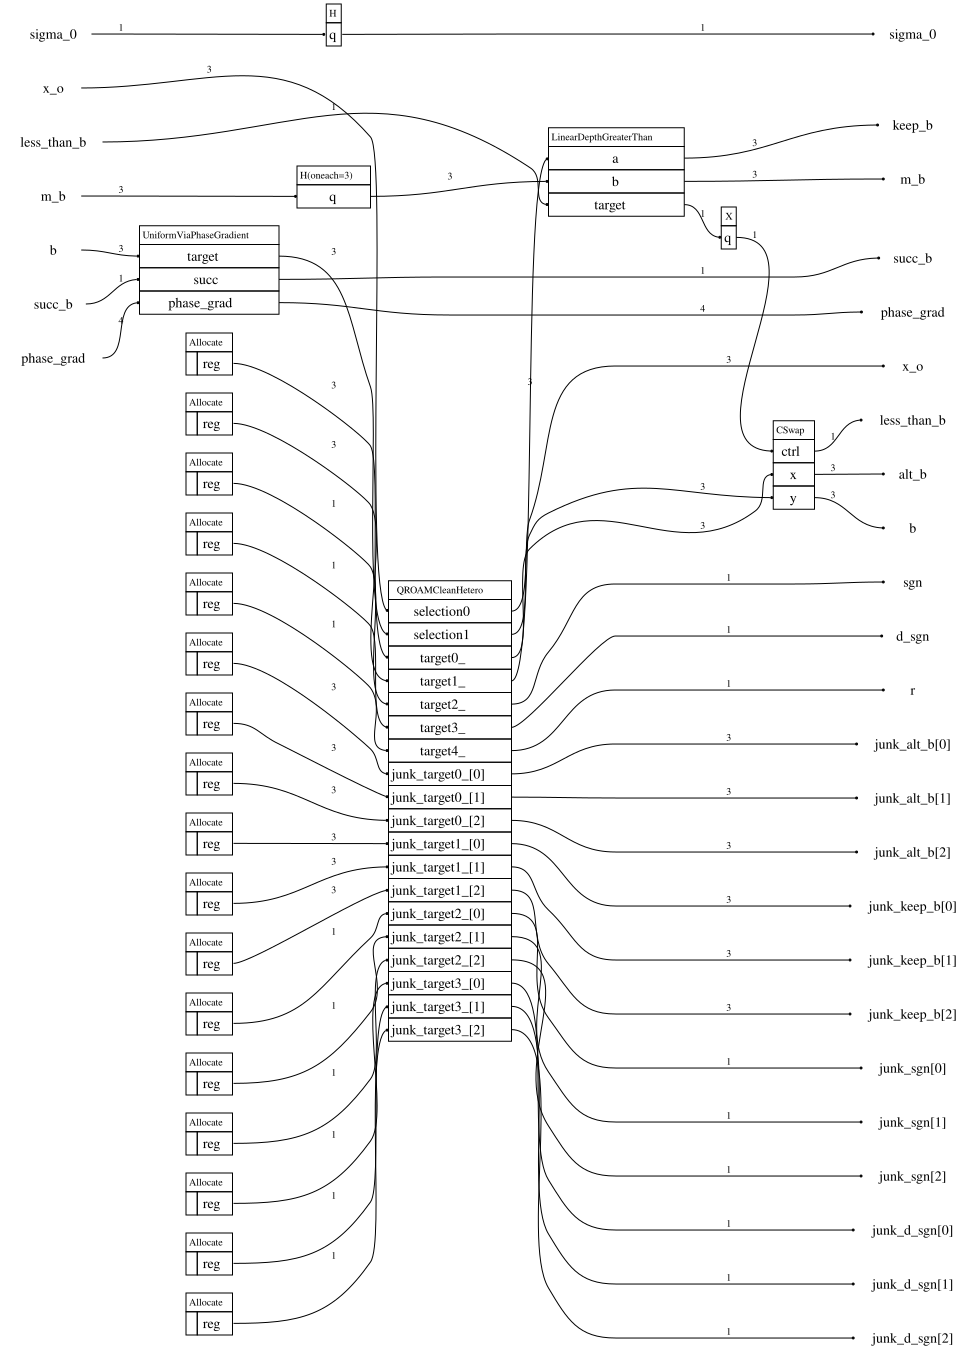

In [13]:
show_bloq(walks['tiny'].block_encoding.inner.decompose_bloq())

In [14]:
sym_inner = walks['symbolic'].block_encoding.inner
B = sympy.Symbol('B')
n_b = sympy.Symbol('n_b', integer=True, nonnegative=True)  # the qubits of b amplified
SHORT_B = [(sym_inner.uniform.k_l_logL()[2], n_b), (sympy.floor(B), B), (N + R * C, X_o)]
for bloq, n in get_bloq_callee_counts(sym_inner):
    toffolis = get_cost_value(bloq, QECGatesCost()).total_toffoli_only()
    print(f'{n} x {bloq}: {sympy.collect(sympy.S(toffolis).subs(SHORT_B), sympy.Min(1, n_b))}')
total = get_cost_value(sym_inner, QECGatesCost()).total_toffoli_only()
print('total:', sympy.collect(total.subs(SHORT_B), sympy.Min(1, n_b)))

1 x UniformViaPhaseGradient: (4*n_b + 2*s_u - 5)*Min(1, n_b)
1 x H: 0
1 x H(oneach=b_k2): 0
1 x QROAMCleanHetero: 2*2**k_2 + C*R*ceiling((B + 1)/2**k_2) + b_k2*(2**k_2 - 1) + (2**k_2 - 1)*ceiling(log2(B + 1)) + beta(C*R, X_o)*s(ceiling((B + 1)/2**k_2)) - 4
1 x LinearDepthGreaterThan: b_k2
1 x X: 0
1 x CSwap: ceiling(log2(B + 1))


total: 2*2**k_2 + C*R*ceiling((B + 1)/2**k_2) + b_k2*(2**k_2 - 1) + b_k2 + (2**k_2 - 1)*ceiling(log2(B + 1)) + (4*n_b + 2*s_u - 5)*Min(1, n_b) + beta(C*R, X_o)*s(ceiling((B + 1)/2**k_2)) + ceiling(log2(B + 1)) - 4


Here $B + 1 = 2^{\eta_b} l_b$ with $l_b$ odd, and $n_b = \lg l_b$ is the number of qubits of $b$ that its equal superposition amplifies.

For the QROAM, $K_2 = 2^{k_2}$ is the block size of the read and $\hat B = \lceil (B+1)/K_2 \rceil$ the number of blocks in a row; $\lg(B+1)$ is the width of $b$, and $b_2 = \lg(B+1) + b_{k_2}$ that of $(\mathrm{alt}, \mathrm{keep})$.

The total costs:
- `UniformViaPhaseGradient`: $3 n_b$ for the three comparisons, $n_b - 1$ for the `MultiAnd` and $2(s_u - 2)$ for the two rotations.
- `H`, `H(oneach=b_k2)` and `X`: the Hadamard on $\sigma_0$, those on $m_b$ and the negation of the flag, all Clifford.
- `QROAMCleanHetero` (step 6), the read:
  - $RC \hat B$: the leaves of the walk over the SF rows, one per block of each of the $RC$ rows.
  - $\beta(RC, X_o)\, s(\hat B)$: the leaves of the $N$ zero rows of the tail. The dead addresses are values of $x_o$, so the walk must stop on them, one stop per aligned block of $[RC, X_o)$, $\beta(RC, X_o)$ (skipping them would alias live rows onto the dead branches), and each stop still carries a pruned sub-walk over the $\hat B$ blocks of $b$, $s(\hat B)$ leaves ($s$ the number of ones in binary). Only one shared walk over $x_o$ with step 10 removes the stops ([#13](https://github.com/Covestro-HPQC/dfthcbe/issues/13)); the part of $s(\hat B)$ beyond one leaf per stop counts extra leaves of Qualtran's unary iteration, zero here since $\hat B = 2$ ([#22](https://github.com/Covestro-HPQC/dfthcbe/issues/22)).
  - $-2$: the QROM walks $\ell$ leaves with $\ell - 2$ ANDs.
  - $(K_2 - 1)(b_2 + 2)$: the swaps, which move copy $b^{\mathrm{lo}}$ to copy 0, $K_2 - 1$ controlled swaps per bit of an entry: the $b_2$ bits of $\mathrm{alt}$ and $\mathrm{keep}$, and the sign bits `sgn` and `d_sgn`. There are no swaps on $r$, the walk writes it directly. In the print, the $2(K_2 - 1)$ of the sign bits and the $-2$ add up to `2*2**k_2 - 4`.
- `LinearDepthGreaterThan` (step 7): $b_{k_2}$, the comparison of $\mathrm{keep}$ with $m_b$.
- `CSwap` (step 8): $\lg(B+1)$, one per qubit of $b$; with step 7, $b_2$.

In [15]:
b_k2, k_2 = sympy.symbols('b_k2 k_2')
total = get_cost_value(sym_inner, QECGatesCost()).total_toffoli_only()
for name, walk in list(walks.items())[:2]:
    inner = walk.block_encoding.inner
    sizes = {N: inner.num_orb, R: inner.num_r, B: inner.num_b, C: inner.num_c, b_k2: inner.b_k2,
             k_2: inner.qroam.log_block_sizes[1], s_u: inner.s}
    built = get_cost_value(inner, QECGatesCost()).total_toffoli_only()
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

tiny: 38 built, 38 from the symbolic count


Fe4S4: 386 built, 386 from the symbolic count


## 6. Steps 10-18: `InnerSelect`

`InnerSelect` applies:

$$
\begin{aligned}
\mathrm{SEL}_b = &\sum_{x_o < RC} |x_o\rangle\langle x_o| \otimes \Big[ \sum_{b < B} |b\rangle\langle b| \otimes \sum_{\sigma_0} |\sigma_0\rangle\langle \sigma_0| \otimes i\, \tilde\gamma_{u^{(r)}_b \sigma_0 0}\, \tilde\gamma_{u^{(r)}_b \sigma_0 1} + |B\rangle\langle B| \otimes I \Big] \\
+ &\sum_{x_o \geq RC} |x_o\rangle\langle x_o| \otimes \sum_{\sigma_1} |\sigma_1\rangle\langle \sigma_1| \otimes \sum_{f} |f\rangle\langle f|_{\sigma_0} \otimes (\pm i)^f\, \tilde\gamma_{u_{x_o} \sigma_1 f},
\end{aligned}
$$

with $\tilde\gamma_{\vec u \sigma f} = \sum_p u_p\, \gamma_{p \sigma f}$ the Majorana operator of flavour $f \in \{0, 1\}$ on spin $\sigma$, rotated onto the unit vector $\vec u$, and $u_{x_o}$ the D1 or Q1 vector of row $x_o$. On an SF row $\sigma_0$ is the spin; on a D1/Q1 row $\sigma_1$ is the spin and $\sigma_0$ the flavour $f$, with $+$ for D1 and $-$ for Q1. Both arrive in $|+\rangle$, so the sums over them are the generators' sums over spin and flavour. All of it acts only where both success flags are set.

It does this in five steps:

1. load the angles $\vec\theta(\vec u)$, first of the one-body terms addressed by $x_o$ that writes additionally the family selector $G$, then the two-body terms addressed by $r$ and $b$, that writes additionally the flag $[b \neq B]$ (steps 10-11);
2. pick the spin: $\sigma = \sigma_{G_0}$, and $U_{\mathrm{Swap}}$ moves that spin's half of the system into `psi_dn` (12-13);
3. rotate with the Givens ladder $U(\vec u)$, which brings $\tilde\gamma_{\vec u}$ onto qubit 0 (14);
4. apply `Maj` to qubit 0, and rotate back (15-16);
5. undo the swap and $\sigma$, and erase the angles (17-18).

The whole bloq for the tiny walk:

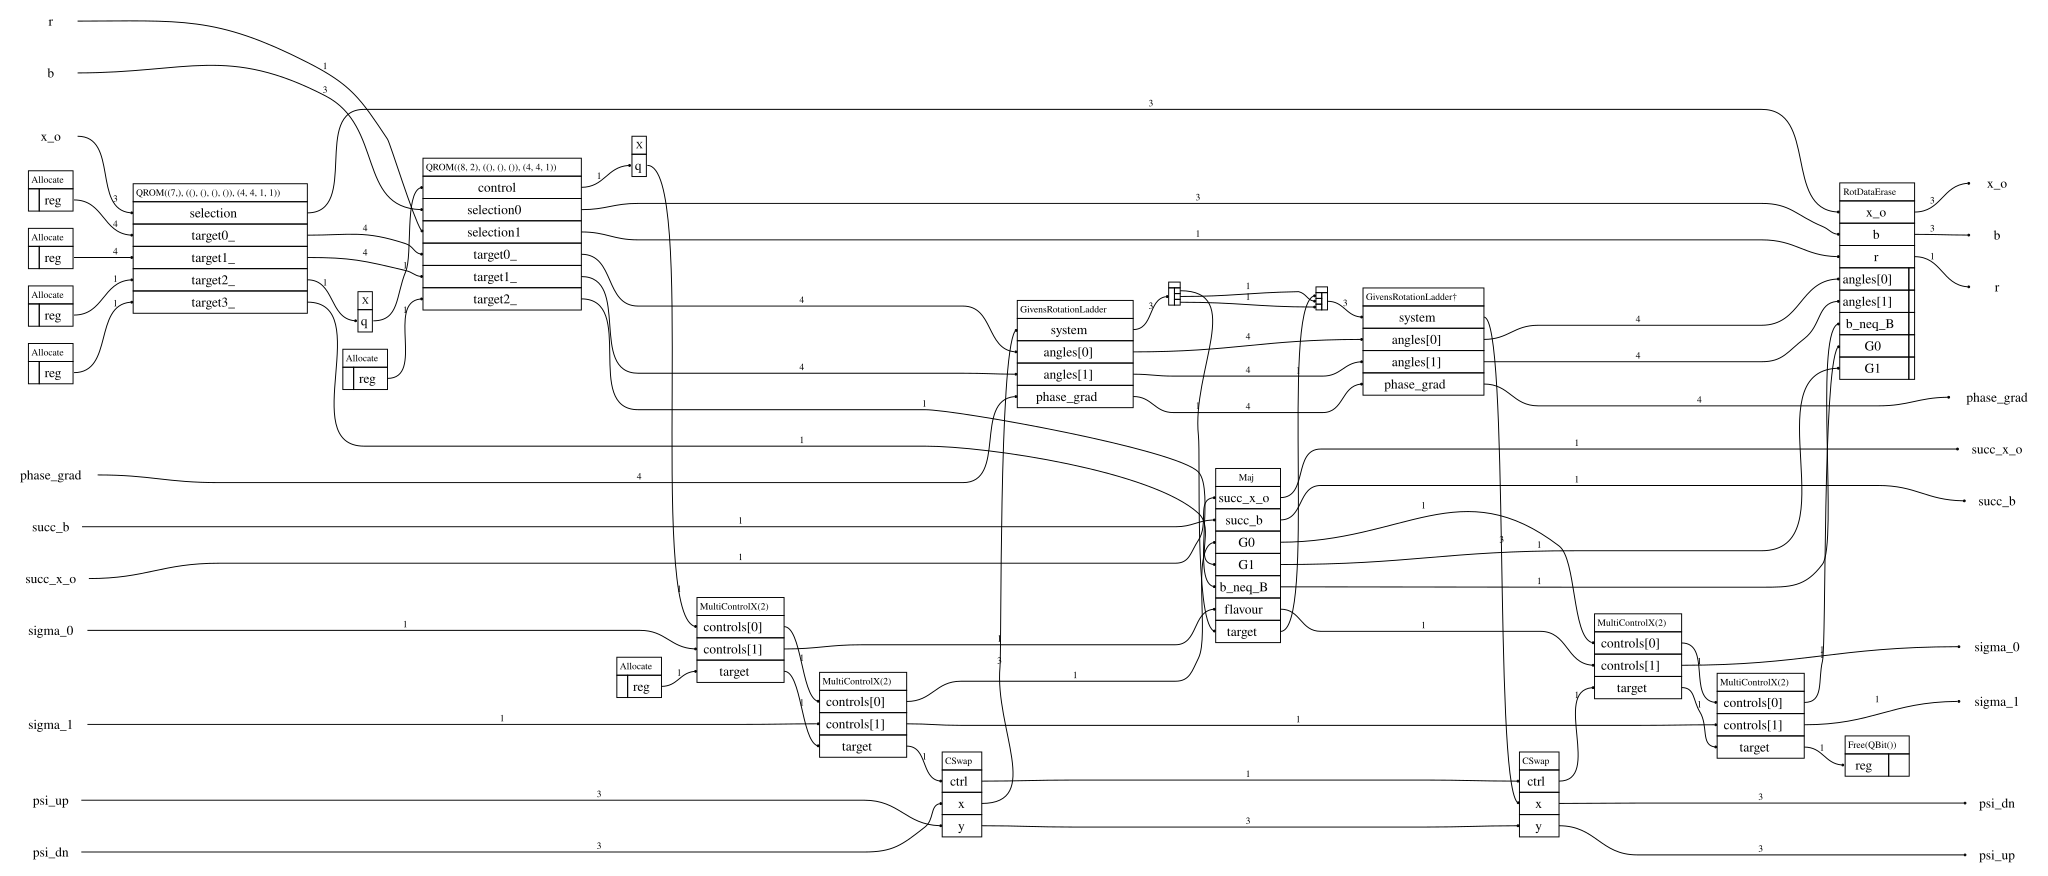

In [16]:
show_bloq(walks['tiny'].block_encoding.select.decompose_bloq())

### 6a. Steps 10-11: the angle loads

Two QROMs fill the same $N - 1$ angle registers of $b_{\mathrm{rot}}$ bits; on any branch only one of them writes. After them, with the alias garbage and the success flags left out, the state is

$$
\begin{aligned}
|\Psi_{11}\rangle = \frac{1}{\lambda_{\mathrm{sqrt}}} \Big[ &\sum_{x_o < RC} \lambda_{x_o}\, |x_o\rangle\, |r\rangle\, |00\rangle_G \sum_{b=0}^{B} (-1)^{\mathrm{sgn}_b} \sqrt{q^{(r,c)}_b}\, |b\rangle\, |\vec\theta(u^{(r)}_b)\rangle\, |[b \neq B]\rangle \\
+ &\sum_{x_o \geq RC} \lambda_{x_o}\, |x_o\rangle\, |0\rangle_r\, |1 g\rangle_G\, |0\rangle_b\, |\vec\theta(u_{x_o})\rangle\, |0\rangle \Big] \otimes |+\rangle_{\sigma_0} |+\rangle_{\sigma_1} \otimes |\psi\rangle,
\end{aligned}
$$

with $g = 0$ for D1 and $1$ for Q1, and $\vec\theta(\vec u)$ the $N - 1$ angles of the ladder that rotates onto $\vec u$ (zero for $b = B$).

Step 10 reads the D1/Q1 angles and $G$ by a unary iteration over $x_o$. The figure shows it for the tiny walk, $RC = 4$ and $N = 3$. (a) The iteration's tree: the zero SF rows $[0, 4)$ are a single aligned block, the three tail rows are live leaves, and $7$ is never visited. (b) The circuit: each live leaf writes its row's angles $\theta_0, \theta_1$ and $G$, $G_0$ on every tail row and $G_1$ on the Q1 row 6.

![Step 10](../docs/dfthc-qrom-tail.svg)

Step 11 reads the SF angles and $[b \neq B]$ the same way, by a unary iteration over $(b, r)$, controlled on $G_0 = 0$.

### 6b. Steps 14 and 16: the Givens ladder

Each rung of the ladder is a `GivensRotationByPhaseGradient` on two neighbouring qubits, with its angle a $b_{\mathrm{rot}}$-bit integer $x$:

$$
\begin{gathered}
|01\rangle \mapsto c|01\rangle + s|10\rangle, \qquad |10\rangle \mapsto -s|01\rangle + c|10\rangle\\
c = \cos\theta, \qquad s = \sin\theta, \qquad \theta = 2\pi x / 2^{b_{\mathrm{rot}} - 1}.
\end{gathered}
$$

The figure is its circuit: a Clifford basis change turns the rotation of $\{|01\rangle, |10\rangle\}$ into two $R_z(\theta)$, and is undone. Each $R_z(\theta)$ is an addition of $x$ into the phase gradient of sec. 4: $x$ is added on $|1\rangle$ and subtracted on $|0\rangle$, a relative phase $e^{i\theta}$, and costs $b_{\mathrm{rot}} - 1$ Toffolis.

![One Givens rung](../docs/dfthc-givens.svg)

The addition is `RzViaPhaseGradient`, a `ControlledAddOrSubtract` around Qualtran's `Add`. On $q = 0$, which the $X$ flips to 1, the CNOTs complement the phase-gradient register, $y \to \bar y$, so the `Add` and the second CNOTs give $\overline{\bar y + x} = y - x$; on $q = 1$ they give $y + x$. Only the `Add` costs Toffolis, its $b_{\mathrm{rot}} - 1$ `And`s:

![Addition into the phase gradient](../docs/dfthc-phase-add.svg)

The ladder, `GivensRotationLadder`, is $N - 1$ rungs, on $(q_{N-2}, q_{N-1})$ down to $(q_0, q_1)$, and carries the rotated orbital onto qubit 0:

$$
U^\dagger(\vec u)\, \gamma_{0 \sigma f}\, U(\vec u) = \tilde\gamma_{\vec u \sigma f}.
$$

For the tiny walk, $N = 3$, two rungs:

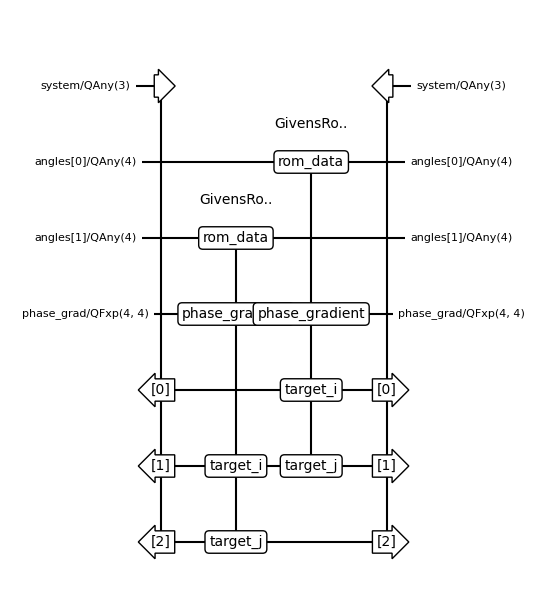

In [17]:
show_bloq(walks['tiny'].block_encoding.select.ladder.decompose_bloq(), 'musical_score')

A check on the tiny walk. Qualtran contracts the ladder with the angles of one SF row loaded as classical inputs and the phase gradient as $|\phi\rangle$ in and out, which leaves $U(\vec u)$ on the three system qubits:

In [18]:
from qualtran import BloqBuilder
from qualtran.bloqs.basic_gates import IntEffect, IntState
from qualtran.bloqs.rotations.phase_gradient import PhaseGradientState

select = walks['tiny'].block_encoding.select  # N = 3 qubits, b_rot = 4
angles = select.angle_data[0][0]  # the angles of the row (r, b) = (0, 0)

bb = BloqBuilder()
system = bb.add_register('system', 3)
theta = np.array([bb.add(IntState(x, 4)) for x in angles])
phase_grad = bb.add(PhaseGradientState(4))
system, theta, phase_grad = bb.add(select.ladder, system=system, angles=theta,
                                   phase_grad=phase_grad)
for t, x in zip(theta, angles):
    bb.add(IntEffect(x, 4), val=t)
bb.add(PhaseGradientState(4).adjoint(), phase_grad=phase_grad)
U = bb.finalize(system=system).tensor_contract()  # 8 x 8

With the Jordan-Wigner Majoranas $\gamma_{p0} = Z \cdots Z X_p$ and $\gamma_{p1} = Z \cdots Z Y_p$, and $\vec u$ the vector the angles encode (`vector_from_angles`), both flavours satisfy $U^\dagger(\vec u)\, \gamma_{0 \sigma f}\, U(\vec u) = \tilde\gamma_{\vec u \sigma f}$:

In [19]:
from functools import reduce
from dfthcbe.rot_data import vector_from_angles

X, Y, Z, I = np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1]), np.eye(2)


def gamma(p, f):
    """The Majorana operator gamma_{p f} on the three system qubits."""
    return reduce(np.kron, [Z] * p + [Y if f else X] + [I] * (2 - p))


u = vector_from_angles(angles, 4)
print('u =', u.round(3))
for f in (0, 1):
    rotated = sum(u[p] * gamma(p, f) for p in range(3))
    print(f'f = {f}:', np.allclose(U.conj().T @ gamma(0, f) @ U, rotated))

u = [-0.707 -0.5    0.5  ]
f = 0: True
f = 1: True


### 6c. Step 15: `Maj`

On qubit 0 the Jordan-Wigner string is empty, so $\gamma_{0 \sigma 0} = X$ and $\gamma_{0 \sigma 1} = Y$, and `Maj` is four gates:

1. on SF rows with $b \neq B$, $i \gamma_0 \gamma_1 = iXY = -Z$, a phase on $t = 0$;
2. on D1/Q1 rows, $X = \gamma_0$;
3. then $Z$ if the flavour $f = \sigma_0$ is 1, as $ZX = iY = i\gamma_1$;
4. and $Z$ on $f$ for Q1, the sign of $iY$.

They must not act where an equal superposition failed: anywhere if $\mathrm{succ}_{x_o} = 0$, and on SF rows if $\mathrm{succ}_b = 0$. D1/Q1 rows do not use $b$, so there a failed $\mathrm{Unif}(b)$ must not turn `Maj` off. Two ANDs give the two conditions: $a = \mathrm{succ}_{x_o} \wedge G_0$ for D1/Q1, and, after a CNOT from $a$ has turned $\mathrm{succ}_{x_o}$ into $\mathrm{succ}_{x_o} \wedge \neg G_0$, $s = \mathrm{succ}_{x_o} \wedge \neg G_0 \wedge \mathrm{succ}_b$ for SF. Gate 1 is controlled on $s$, gates 2-4 on $a$, and both ANDs are undone by measurement.

![Maj](../docs/dfthc-maj.svg)

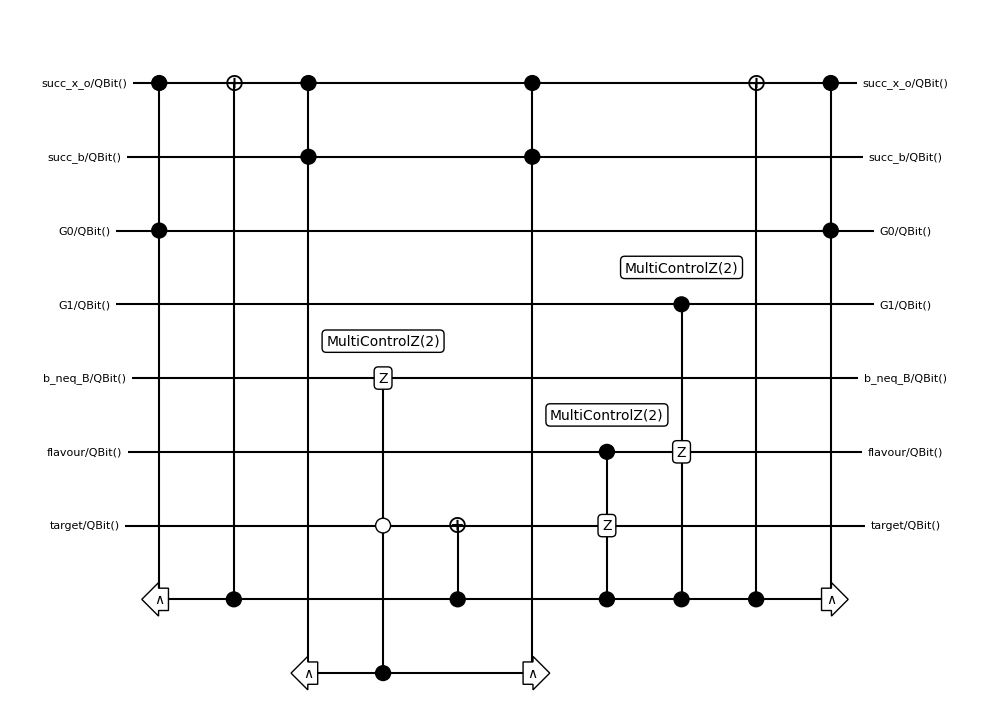

In [20]:
show_bloq(Maj().decompose_bloq(), 'musical_score')

Qualtran contracts `Maj` to its $128 \times 128$ matrix, on $\mathrm{succ}_{x_o}$, $\mathrm{succ}_b$, $G_0$, $G_1$, $[b \neq B]$, $f$ and $t$. With $\mathrm{succ}_{x_o} = 1$, fixing $\mathrm{succ}_b$, $G_0$, $G_1$ and $[b \neq B]$, and projecting the flavour on $|+\rangle$, gives the operator $\langle + | \mathrm{Maj} | + \rangle$ on $t$. It should be $-Z$ on an SF row with $b \neq B$, $I$ for $b = B$, and $(X + iY)/2 = |0\rangle\langle 1|$ for D1 and $(X - iY)/2 = |1\rangle\langle 0|$ for Q1, the annihilation and creation operators ($|1\rangle$ occupied). With $\mathrm{succ}_b = 0$ the SF row is the identity and the D1 row unchanged:

In [21]:
U = Maj().tensor_contract()  # on (succ_x_o, succ_b, G0, G1, b_neq_B, f, t), t the last
plus = np.kron([[1], [1]], np.eye(2)) / np.sqrt(2)  # |+> on f, times the identity on t


def on_t(G0, G1, b_neq_B, succ_b=1):
    """<+|_f Maj |+>_f on t, for fixed succ_b, G0, G1 and b != B, with succ_x_o = 1."""
    k = 64 + 32 * succ_b + 16 * G0 + 8 * G1 + 4 * b_neq_B
    return (plus.T @ U[k:k + 4, k:k + 4] @ plus).real.round().astype(int)


print(on_t(G0=0, G1=0, b_neq_B=1))  # SF, b != B: -Z
print(on_t(G0=0, G1=0, b_neq_B=0))  # SF, b = B: I
print(on_t(G0=1, G1=0, b_neq_B=0))  # D1: |0><1|
print(on_t(G0=1, G1=1, b_neq_B=0))  # Q1: |1><0|
print(on_t(G0=0, G1=0, b_neq_B=1, succ_b=0))  # SF, Unif(b) failed: I
print(on_t(G0=1, G1=0, b_neq_B=0, succ_b=0))  # D1, Unif(b) failed: still |0><1|

[[-1  0]
 [ 0  1]]
[[1 0]
 [0 1]]
[[0 1]
 [0 0]]
[[0 0]
 [1 0]]
[[1 0]
 [0 1]]
[[0 1]
 [0 0]]


### 6d. Step 18: erasing the angles

The angle registers, $[b \neq B]$ and $G$ hold a function of the address, so `RotDataErase` erases them by measurement instead of reading them again:

1. measure them in the $X$ basis, with outcome $\xi$: this frees them, but leaves on each branch the sign $(-1)^{\xi \cdot d}$, with $d$ the data that branch held;
2. pay the signs of the SF load with a walk over $(b, r)$;
3. pay the signs of the tail load with a walk over $x_o$.

Each walk puts on every address the sign $F = \xi \cdot d$ of its data, computed classically from $\xi$.

**The $(b, r)$ walk**, for the tiny walk, $(R, B + 1) = (2, 8)$. First $b$ is turned into a one-hot: seven controlled swaps, of which the first is two CNOTs, move a single 1 onto $y_b$, for $(B + 1) - 2$ Toffolis. Then the walk over $r$ applies, at the leaf of row $r$, a $CZ$ from the leaf onto every $y_j$ with $F_r(j) = 1$. That $CZ$ gives $-1$ only to the branches where both are 1, i.e. $(b, r) = (j, r)$, so every branch picks up exactly its own $(-1)^{F_r(b)}$, which cancels the sign the measurement left. The walk has $R$ leaves, $R - 2$ Toffolis. Here $r$ is a single qubit, so its two values are the leaves, $r[0]$ between two $X$ gates for $r = 0$ and $r[0]$ itself for $r = 1$, for no Toffoli. Undoing the one-hot is free too, as each swap now ends on a qubit known to be 0.

The figure takes an outcome $\xi$ that gives $F_0 = (1, 0, 0, 1, 0, 0, 0, 0)$ and $F_1 = (0, 0, 0, 1, 0, 1, 0, 0)$: four $CZ$ gates, each classically controlled on $\xi$. $b = 0$ gets a sign for $r = 0$ but not for $r = 1$, as $F$ depends on the whole address $(b, r)$. $F_r(B)$ is always 0, as the row $b = B$ loaded nothing.

![The (b, r) walk of step 18](../docs/dfthc-rot-erase-sf.svg)

**The $x_o$ walk** is the walk of step 10 again, for the tiny walk, $RC = 4$ and $N = 3$, with a $Z^{F_{x_o}}$, classically controlled on $\xi$, on each leaf where step 10 wrote the data. It has to get past the zero SF rows $[0, 4)$ first. They are a single aligned block, one leaf and no sign, as $4 = 100$ in binary: $s(RC)$ leaves. The $N$ tail rows are a leaf each, so the walk has $N + s(RC)$ leaves, and $N + s(RC) - 2$ ANDs.

![The x_o walk of step 18](../docs/dfthc-rot-erase-tail.svg)

Neither walk is controlled. On the D1/Q1 rows $b = r = 0$, so the $(b, r)$ walk leaves a constant sign there, which the $x_o$ walk cancels by flipping its tail signs by that constant.

### 6e. The cost

In [22]:
sym_select = walks['symbolic'].block_encoding.select
for bloq, n in get_bloq_callee_counts(sym_select):
    print(f'{n} x {bloq}: {get_cost_value(bloq, QECGatesCost()).total_toffoli_only()}')
print('total:', get_cost_value(sym_select, QECGatesCost()).total_toffoli_only())

1 x QROM((C*R + N,), ((), (), ()), (b_rot*(N - 1), 1, 1)): N + s(C*R) - 2
1 x QROM((B + 1, R), ((), ()), (b_rot*(N - 1), 1)): B*R + s(R) - 1
2 x X: 0
2 x MultiControlX(2): 1
2 x MultiControlX(2): 1
2 x CSwap: N
1 x GivensRotationLadder: (N - 1)*(2*b_rot - 2)
1 x Maj: 5
1 x GivensRotationLadder†: (N - 1)*(2*b_rot - 2)
1 x RotDataErase: B + N + R + s(C*R) - 5
total: B*R + B + 4*N + R + 2*(N - 1)*(2*b_rot - 2) + s(R) + 2*s(C*R) + 1


- `QROM((C*R + N,), ...)` (step 10): $N + s(RC) - 2$, the $N$ live leaves and $s(RC)$ for the zero SF rows the walk has to get past, minus 2, as the QROM walks $\ell$ leaves with $\ell - 2$ ANDs. One walk over $x_o$ for steps 6 and 10 would save the $s(RC)$ ([#13](https://github.com/Covestro-HPQC/dfthcbe/issues/13)).
- `QROM((B + 1, R), ...)` (step 11): $RB + s(R) - 1$, the $RB$ live leaves and $s(R)$ for the zero row $b = B$: one stop for it, needed as above, and $s(R) - 1$ more, extra leaves of Qualtran's unary iteration ([#22](https://github.com/Covestro-HPQC/dfthcbe/issues/22)), minus 1, as a walk with $k$ controls takes $\ell + k - 2$ ANDs.
- `X`: the two $X$ that fire step 11 on $G_0 = 0$, Clifford.
- `MultiControlX(2)`, both twice: building and unbuilding $\sigma = \sigma_{G_0}$, 1 Toffoli each (steps 12, 17).
- `CSwap`: $U_{\mathrm{Swap}}$ and its undo, $N$ each (steps 13, 17).
- `GivensRotationLadder` and its adjoint: $N - 1$ rungs of $2(b_{\mathrm{rot}} - 1)$ (steps 14, 16).
- `Maj`: 5, the two ANDs that combine the flags with $G_0$ and the three CCZs of gates 1, 3 and 4; gate 2 is a CNOT (step 15).
- `RotDataErase` (step 18): $B + R + N + s(RC) - 5$, the two fixups of 6d: the one-hot, $(B + 1) - 2$, and the walk over $r$, $R - 2$; and the walk over $x_o$, $N + s(RC) - 2$.

In [23]:
b_rot = sympy.Symbol('b_rot')
total = get_cost_value(sym_select, QECGatesCost()).total_toffoli_only()
for name, walk in list(walks.items())[:2]:
    select = walk.block_encoding.select
    sizes = {N: select.num_orb, R: select.num_r, B: select.num_b, C: select.num_c,
             b_rot: select.b_rot}
    built = get_cost_value(select, QECGatesCost()).total_toffoli_only()
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

tiny: 63 built, 63 from the symbolic count
Fe4S4: 2522 built, 2522 from the symbolic count


## 7. Steps 19-22: the inner unprepare, `InnerPrepare.adjoint()`

After `InnerSelect`, steps 19-22 return every inner ancilla to $|0\rangle$. To do that, we reverse the order of the Prepare step:

1. swap $\mathrm{alt}$ back out of $b$, on the same flag $\mathrm{less\_than}_b$ (19)
2. clear the flag: the $X$ and the comparison of step 7 again (20)
3. erase the data at the address $(x_o, b)$ (21)
4. undo the equal superposition over $b$, and the Hadamards on $m_b$ and $\sigma_0$ (22).

On the D1/Q1 rows the flag is 1 everywhere, so step 19 moves the uniform superposition back from $\mathrm{alt}$ into $b$, and step 22 undoes it.

![Steps 19-22](../docs/dfthc-inner-unprepare.svg)

The sign step 9 is not undone, to obtain the correct LCU signs.

### 7a. Step 21: the erase

The data registers now hold the entry at the address $(x_o, b)$: $\mathrm{alt}$, $\mathrm{keep}$, the two sign bits `sgn` and `d_sgn`, $r$ and the junk copies of step 6, together $d(x_o, b)$. Measuring them in the $X$ basis, with outcome $\xi$, frees them, but leaves on the branch of each address the sign $(-1)^{\xi \cdot d(x_o, b)}$, with $\xi \cdot d$ the parity of the outcomes $\xi_i$ on the bits where $d_i = 1$. A phase fixup on the address pays these signs back. The $N$ D1/Q1 rows hold no data, $d = 0$, so they need no fixup.

The fixup splits the address in two, with $K_{e2} = 2^{k_{e2}}$:

1. a one-hot over $b$ and the low $k_{e2}$ bits of $x_o$, $x_o^{\mathrm{lo}}$: $K_{e2}(B + 1)$ qubits, one per pair $(x_o^{\mathrm{lo}}, b)$, of which only the one of the address is 1;
2. a unary iteration over the other bits of $x_o$, $x_o^{\mathrm{hi}} = \lfloor x_o / K_{e2} \rfloor$. Its leaf $m$ is active on the rows $x_o = m K_{e2}, \dots, (m + 1) K_{e2} - 1$, and applies a $CZ$ from the leaf onto every one-hot qubit whose entry has sign bit 1. A branch has only its own leaf and its own one-hot qubit at 1, so it gets exactly its own sign back.

The iteration has leaves with signs on the SF rows only, and leaves without gates on the zero rows, which keep the SF leaves off them.

The figure is the tiny walk, where the cheapest $k_{e2}$ is 0: the one-hot holds $b$ alone, $y_j = [b = j]$, and the iteration runs over all of $x_o$. Leaf $x_o$ covers the row $x_o$, and $F_{x_o}[j]$ is the sign bit $\xi \cdot d$ of the entry $(x_o, j)$. The figure takes an outcome $\xi$ that gives $F_0 = (0,1,0,0,0,1,0,0)$, $F_1 = (1,0,0,0,1,0,0,0)$, $F_2 = (0,0,1,1,0,0,0,0)$ and $F_3 = (0,1,0,0,0,0,0,0)$: seven $CZ$ gates, each classically controlled on $\xi$. The zero rows $4, 5, 6$ get the two leaves $[4, 6)$ and $\{6\}$, without gates, which keep the SF leaves off them.

![Step 21](../docs/dfthc-inner-alias-erase.svg)

The erase is `QROAMCleanHetero.adjoint()`, printed as `QROAMCleanAdjoint`. It charges this circuit without building it, as the measurement has no unitary decomposition. The whole bloq for the tiny walk:

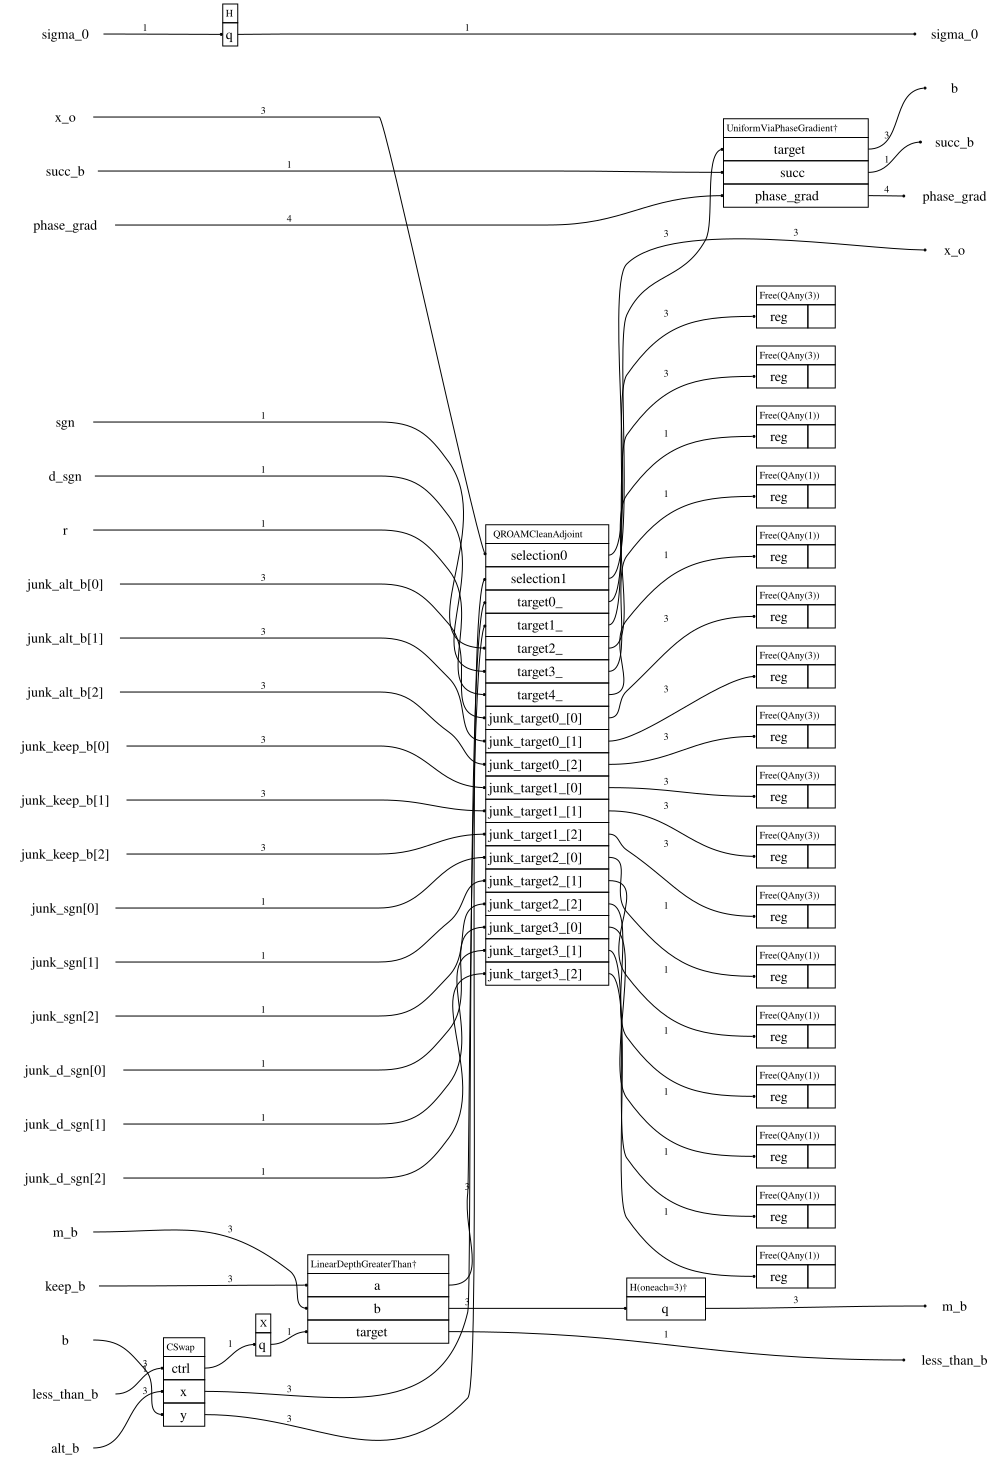

In [24]:
show_bloq(walks['tiny'].block_encoding.inner.adjoint().decompose_bloq())

### 7b. The cost

In [25]:
sym_unprep = walks['symbolic'].block_encoding.inner.adjoint()
for bloq, n in get_bloq_callee_counts(sym_unprep):
    toffolis = get_cost_value(bloq, QECGatesCost()).total_toffoli_only()
    print(f'{n} x {bloq}: {sympy.collect(sympy.S(toffolis).subs(SHORT_B), sympy.Min(1, n_b))}')
total = get_cost_value(sym_unprep, QECGatesCost()).total_toffoli_only()
print('total:', sympy.collect(total.subs(SHORT_B), sympy.Min(1, n_b)))

1 x UniformViaPhaseGradient†: (4*n_b + 2*s_u - 5)*Min(1, n_b)
1 x H: 0
1 x H(oneach=b_k2)†: 0
1 x QROAMCleanAdjoint: 2**k_e2*(B + 1) + beta(ceiling(C*R/2**k_e2), ceiling(X_o/2**k_e2)) + ceiling(C*R/2**k_e2) - 4
1 x LinearDepthGreaterThan†: b_k2
1 x X: 0
1 x CSwap: ceiling(log2(B + 1))
total: 2**k_e2*(B + 1) + b_k2 + (4*n_b + 2*s_u - 5)*Min(1, n_b) + beta(ceiling(C*R/2**k_e2), ceiling(X_o/2**k_e2)) + ceiling(C*R/2**k_e2) + ceiling(log2(B + 1)) - 4


- `UniformViaPhaseGradient†` (step 22): the same as step 5, $3 n_b$, $n_b - 1$ and $2(s_u - 2)$, and 0 if $B + 1$ is a power of two.
- `H`, `H(oneach=b_k2)†` and `X`: $\sigma_0$, $m_b$ and the flag, all Clifford.
- `QROAMCleanAdjoint` (step 21), the erase of sec. 7a:
  - $K_{e2}(B + 1)$: the one-hot, one qubit per pair $(x_o^{\mathrm{lo}}, b)$. A single 1 is moved onto the qubit of the address by $K_{e2}(B + 1) - 1$ controlled swaps, one Toffoli each, except the first: it acts on two qubits known to be 1 and 0, so it is two CNOTs.
  - $\lceil RC / K_{e2} \rceil$: the leaves on the SF rows, one per value of $x_o^{\mathrm{hi}}$ that holds an SF row. Their $CZ$s are Clifford.
  - $\beta(\lceil RC / K_{e2} \rceil, \lceil X_o / K_{e2} \rceil)$: the leaves that keep the iteration off the zero rows. $x_o^{\mathrm{hi}}$ runs up to $\lceil X_o / K_{e2} \rceil$, and the iteration can only tell the values past the SF rows apart from the SF leaves in aligned power-of-two blocks, one leaf each; $\beta$ counts them, as in sec. 5. These stops are needed as in step 6; one shared walk over $x_o$ for steps 18 and 21 removes them ([#13](https://github.com/Covestro-HPQC/dfthcbe/issues/13)). In the figure they are the two leaves without gates, $[4, 6)$ and $\{6\}$.
  - $-4$: $-2$ from the one-hot, which has one swap fewer than qubits and the first one free, and $-2$ because the iteration walks $\ell$ leaves with $\ell - 2$ ANDs, as for the reads.
  - The measurement, the $CZ$s and undoing the one-hot cost nothing.

  By default $k_{e2}$ is the cheapest; for the tiny walk it is 0, so its one-hot holds $b$ alone.
- `LinearDepthGreaterThan†` (step 20): $b_{k_2}$, the comparison again.
- `CSwap` (step 19): $\lg(B+1)$, the swap back.

In [26]:
k_e2 = sympy.Symbol('k_e2')
total = get_cost_value(sym_unprep, QECGatesCost()).total_toffoli_only()
for name, walk in list(walks.items())[:2]:
    inner = walk.block_encoding.inner
    sizes = {N: inner.num_orb, R: inner.num_r, B: inner.num_b, C: inner.num_c, b_k2: inner.b_k2,
             k_e2: inner.qroam.erase_log_block_sizes[0], s_u: inner.s}
    built = get_cost_value(inner.adjoint(), QECGatesCost()).total_toffoli_only()
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

tiny: 16 built, 16 from the symbolic count
Fe4S4: 109 built, 109 from the symbolic count


## 8. Step 23: `REF_T2`

The reflection about $|0\rangle_B |1\rangle_{\mathrm{succ}_{x_o}}$, with $B$ the inner ancillas $b, m_b, \sigma_0$: $2|0\rangle\langle 0|_B - I$ where $\mathrm{Unif}(x_o)$ worked, and $-I$ where it failed.

![The identity behind REF_T2](../docs/dfthc-t2.svg)

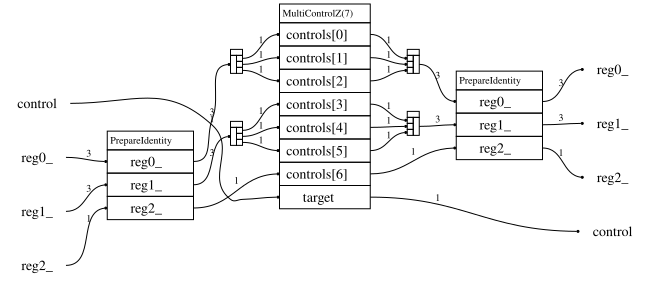

In [27]:
show_bloq(walks['tiny'].block_encoding.ref_t2.decompose_bloq())

Qualtran builds every reflection about a prepared state $|s\rangle = P|0\rangle$ as $P\,(I - 2|0\rangle\langle 0|)\,P^\dagger$, times a global phase. Here the state is $|0\rangle$ itself, so $P$ is `PrepareIdentity`, which does nothing: the two boxes only mark where $P^\dagger$ and $P$ go. The reflection is the `MultiControlZ`, with open controls on the seven reflected qubits $b$, $m_b$ and $\sigma_0$ and its $Z$ on $\mathrm{succ}_{x_o}$, so it puts $-1$ on the all-zero state where $\mathrm{succ}_{x_o} = 1$. The block encoding adds the $-1$ that turns $I - 2|0\rangle\langle 0|$ into $2|0\rangle\langle 0| - I$ as a global phase of its own, `ref_t2_phase`, a $Z$ on `ctrl` when the walk is controlled. So where $\mathrm{Unif}(x_o)$ failed, $\mathrm{REF}_{T_2}$ is $-I$, which only raises $\Lambda$ to $\Lambda / (1 - P(\mathrm{succ}_{x_o} = 0))$. Qualtran's controlled reflection would put that $-1$ on $\mathrm{succ}_{x_o}$ instead, making the failed branch $+I$, a shift of $H_{\mathrm{SA}}$ ([#39](https://github.com/Covestro-HPQC/dfthcbe/issues/39)). A `MultiControlZ` with $n$ controls costs $n - 1$ Toffolis, here $n = b_2 + 1$.

In [28]:
total = get_cost_value(walks['symbolic'].block_encoding.ref_t2, QECGatesCost()).total_toffoli_only()
print('symbolic:', total.subs(SHORT_B))
for name, walk in list(walks.items())[:2]:
    inner = walk.block_encoding.inner
    built = get_cost_value(walk.block_encoding.ref_t2, QECGatesCost()).total_toffoli_only()
    sizes = {B: inner.num_b, b_k2: inner.b_k2}
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

symbolic: b_k2 + ceiling(log2(B + 1))
tiny: 6 built, 6 from the symbolic count
Fe4S4: 19 built, 19 from the symbolic count


## 9. Steps 24-27: the outer unprepare, `OuterPrepare.adjoint()`

After the mirror of steps 5-22, steps 24-27 undo steps 1-4 as sec. 7 undid steps 5-8, over $x_o$ alone: swap $\mathrm{alt}$ back out of $x_o$ (24), clear the flag (25), erase $\mathrm{alt}$, $\mathrm{keep}$ and the junk copies (26), and undo the equal superposition over $x_o$ and the Hadamards on $m_{x_o}$ and $\sigma_1$ (27). The erase is `QROAMCleanAdjoint` again, in blocks of $K_{e1} = 2^{k_{e1}}$: $K_{e1} + \lceil X_o / K_{e1} \rceil - 4$ Toffolis. The whole bloq for the tiny walk:

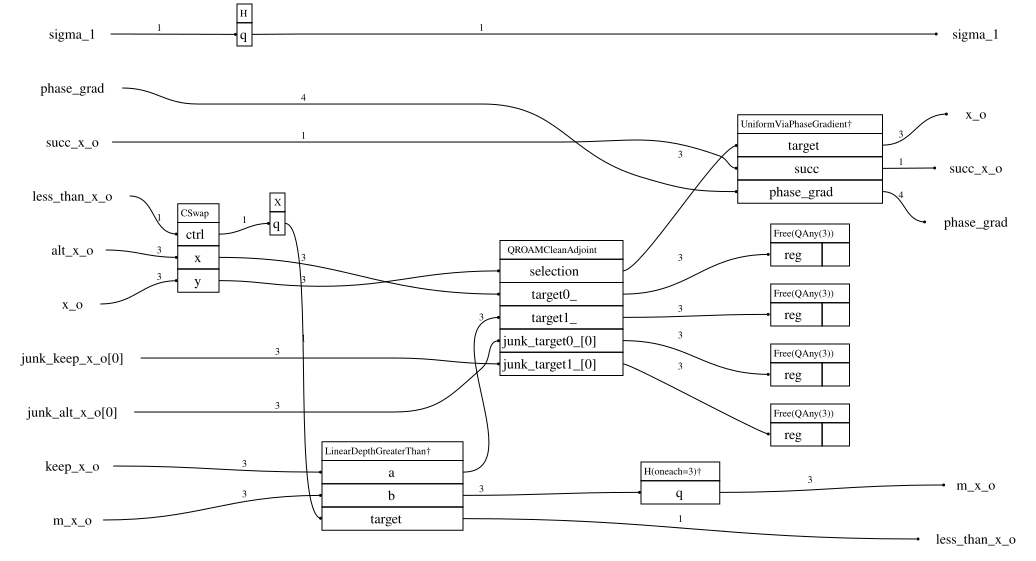

In [29]:
show_bloq(walks['tiny'].block_encoding.outer.adjoint().decompose_bloq())

In [30]:
sym_outer_unprep = walks['symbolic'].block_encoding.outer.adjoint()
for bloq, n in get_bloq_callee_counts(sym_outer_unprep):
    toffolis = get_cost_value(bloq, QECGatesCost()).total_toffoli_only()
    print(f'{n} x {bloq}: {sympy.collect(sympy.S(toffolis).subs(SHORT), sympy.Min(1, n_x))}')

1 x UniformViaPhaseGradient†: (4*n_x + 2*s_u - 5)*Min(1, n_x)
1 x H(oneach=b_k1)†: 0
1 x H: 0
1 x QROAMCleanAdjoint: 2**k_e1 + ceiling(X_o/2**k_e1) - 4
1 x LinearDepthGreaterThan†: b_k1
1 x X: 0
1 x CSwap: ceiling(log2(X_o))


In [31]:
k_e1 = sympy.Symbol('k_e1')
total = get_cost_value(sym_outer_unprep, QECGatesCost()).total_toffoli_only()
total = total.subs(N + R * C, X_o)
for name, walk in list(walks.items())[:2]:
    outer = walk.block_encoding.outer
    sizes = {X_o: outer.num_x, b_k1: outer.b_k1, k_e1: outer.qroam.erase_log_block_sizes[0],
             s_u: outer.s}
    built = get_cost_value(outer.adjoint(), QECGatesCost()).total_toffoli_only()
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

tiny: 23 built, 23 from the symbolic count
Fe4S4: 85 built, 85 from the symbolic count


## 10. Step 28: `REF_aB`

A reflection on the outer and inner ancillas together.

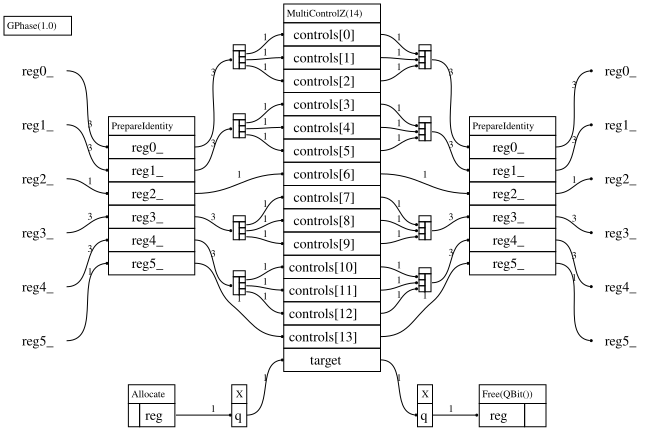

In [32]:
show_bloq(walks['tiny'].ref_ab.decompose_bloq())

The same construction, uncontrolled, on all fourteen ancilla qubits of the tiny walk: $x_o$, $m_{x_o}$, $\sigma_1$, $b$, $m_b$ and $\sigma_0$. With no control qubit to put the $Z$ on, Qualtran allocates one and sets it to $|1\rangle$ (the `X`), so the `MultiControlZ` puts $-1$ on the all-zero state, and frees it after. `GPhase(1.0)` is the global phase $e^{i\pi} = -1$. Again $n - 1$ Toffolis, for $n = b_1 + b_2 + 2$.

In [33]:
total = get_cost_value(walks['symbolic'].ref_ab, QECGatesCost()).total_toffoli_only()
print('symbolic:', total.subs(SHORT).subs(SHORT_B))
for name, walk in list(walks.items())[:2]:
    outer, inner = walk.block_encoding.outer, walk.block_encoding.inner
    built = get_cost_value(walk.ref_ab, QECGatesCost()).total_toffoli_only()
    sizes = {N: inner.num_orb, R: inner.num_r, B: inner.num_b, C: inner.num_c,
             b_k1: outer.b_k1, b_k2: inner.b_k2}
    print(f'{name}: {built} built, {total.subs(sizes)} from the symbolic count')

symbolic: b_k1 + b_k2 + ceiling(log2(X_o)) + ceiling(log2(B + 1)) + 1
tiny: 13 built, 13 from the symbolic count
Fe4S4: 43 built, 43 from the symbolic count


## 11. The comparison with Low *et al.*

Our column is, row by row, what the symbolic bloqs of secs. 4-10 return; theirs is the equation of the paper cited, per call. Each pair of steps is a forward pass and its adjoint, which cost the same, and each erase includes undoing the test and the swap.

![The walk's Toffolis in closed form](../docs/dfthc-costs-symbolic.svg)

Here $b_1$ and $b_2$ are the widths of $(\mathrm{alt}, \mathrm{keep})$ of secs. 4 and 5; their $b_2$ (B36) also counts a sign bit, so their B37 and B50 read $b_2 + 1$ here; $M_1 = \lceil X_o / K_1 \rceil$ and $M_2 = RC \hat B$ are the live leaves of the two reads; $\beta_N = \beta(RC, X_o)$; and $K_4 = 2^{k_4}(B + 1)$ and $K_5 = 2^{k_5}$ are the paper's erase blocks.

The paper gives numbers for FeMoco-54 only: $N = 54$, $(R, B, C) = (10, 27, 27)$, $b_{\mathrm{rot}} = b_{k_1} = b_{k_2} = 15$, $s_u = 7$, $(k_1, k_2, k_{e1}, k_{e2}) = (2, 4, 4, 2)$ and their $(k_4, k_5) = (2, 4)$. Their column is their Table III, with the phase fixup of the D1/Q1 angles, $N$, counted at step 18, where `dfthcbe` applies it, rather than at step 21:

![The walk's Toffolis at FeMoco-54](../docs/dfthc-costs-femoco.svg)

The walk is $306 + 2 \cdot 1133 + 2 \cdot 3502 + 20 + 45 = 9641$ Toffolis against their $310 + 2 \cdot 1100 + 2 \cdot 3710 + 21 + 46 = 9997$, every rotation included in ours. Their Table III evaluates B37 and B50 at $b_2 = 20$, so their closed forms give $9997 + 34$.